   Hours Studied  ...  Performance Index
0              7  ...               91.0
1              4  ...               65.0
2              8  ...               45.0
3              5  ...               36.0
4              7  ...               66.0

[5 rows x 6 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB
None
       Hours Studied  ...  Performance Index
count  

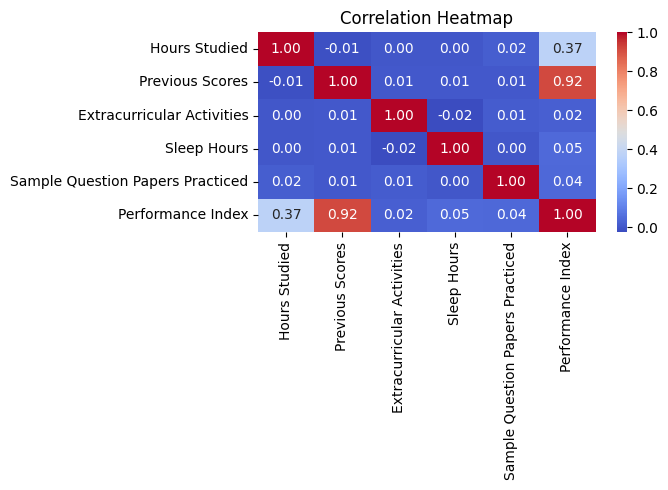


=== SIMPLE LINEAR REGRESSION ===
Interscept (b0):  41.436634826535744
slope (b1)     :  2.784300441170774
R2    :  0.13160425385996788
RMSE  :  17.93919001285204


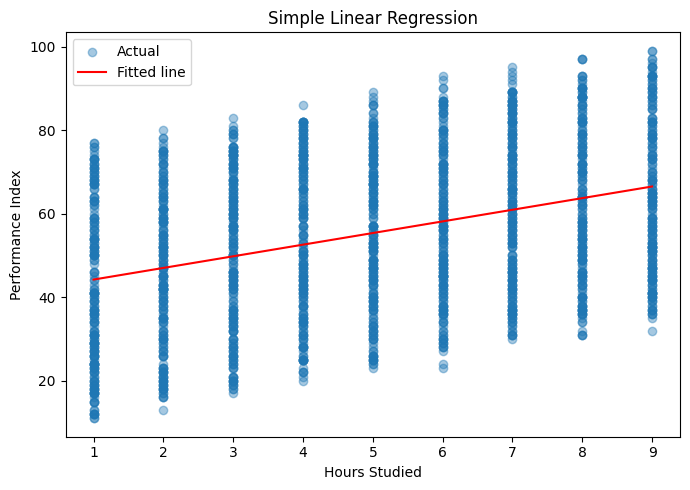


=== MULTIPLE LINEAR REGRESSION ===
Intercept: -33.92194621555638
 Hours Studied                       2.8525
 Previous Scores                     1.0170
 Extracurricular Activities          0.6086
 Sleep Hours                         0.4769
 Sample Question Papers Practiced    0.1918
R2 : 0.9889832909573145
Adjusted R2 : 0.9889556663107681
RMSE : 2.0205515085050054


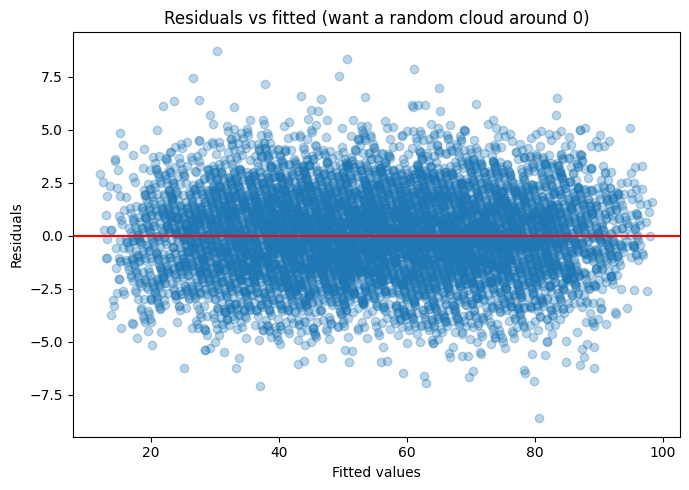

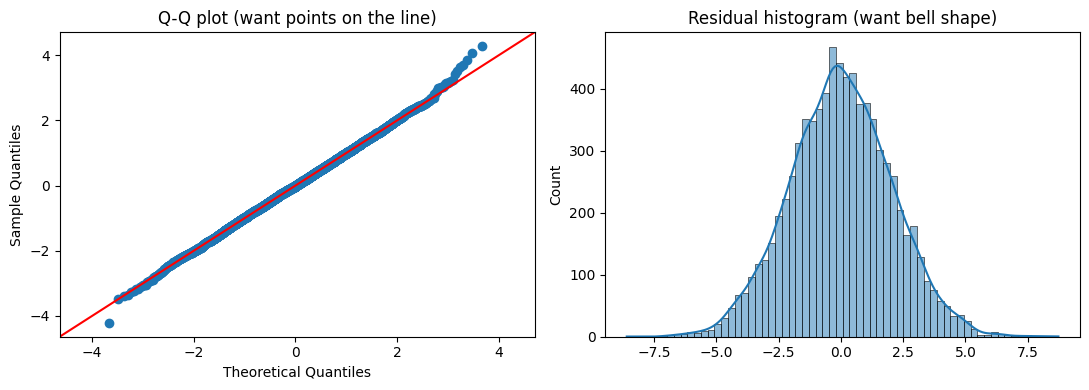

Breusch-Pagan p-value: 0.2396245087908097
Durbin-Watson: 2.0331060225040156

VIF:
                             Feature       VIF
1                     Hours Studied  1.000387
2                   Previous Scores  1.000243
3        Extracurricular Activities  1.000428
4                       Sleep Hours  1.000461
5  Sample Question Papers Practiced  1.000320


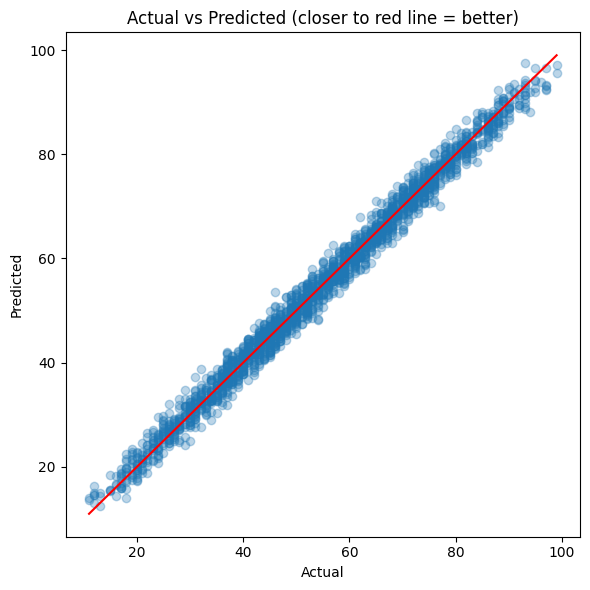

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error


df = pd.read_csv("Student_Performance.csv")
print(df.head())
print(df.info())
print(df.describe())
print("Missing values:\n", df.isnull().sum())


df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes": 1, "No": 0})



plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()

X_simple = df[["Hours Studied"]]
y = df["Performance Index"]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)
simple_model = LinearRegression()
simple_model.fit(Xs_train, ys_train)

print("\n=== SIMPLE LINEAR REGRESSION ===")
print("Interscept (b0): ", simple_model.intercept_)
print("slope (b1)     : ", simple_model.coef_[0])

ys_pred = simple_model.predict(Xs_test)
print("R2    : ", r2_score(ys_test, ys_pred))
print("RMSE  : ", np.sqrt(mean_squared_error(ys_test, ys_pred)))


plt.figure(figsize=(7, 5))
plt.scatter(Xs_test, ys_test, alpha=0.4, label="Actual")
plt.plot(
    Xs_test.sort_values("Hours Studied"),
    simple_model.predict(Xs_test.sort_values("Hours Studied")),
    color="red",
    label="Fitted line"
)
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.title("Simple Linear Regression")
plt.legend()
plt.savefig("02_simple_fit.png")
plt.tight_layout()
plt.show()


X = df.drop(columns="Performance Index")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

print("\n=== MULTIPLE LINEAR REGRESSION ===")
print("Intercept:", multi_model.intercept_)
for name, coef in zip(X.columns, multi_model.coef_):
    print(f" {name:35s} {coef:.4f}")

# Model evaluation metrics
y_pred = multi_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("R2 :", r2)
print("Adjusted R2 :", adj_r2)
print("RMSE :", rmse)

# 4. Checking Assumptions
X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
fitted = ols.fittedvalues
resid = ols.resid

# 4a. Residuals vs Fitted
plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs fitted (want a random cloud around 0)")
plt.tight_layout()
plt.savefig("03_resid_vs_fitted.png")
plt.show()

# 4b. Normality of residuals
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sm.qqplot(resid, line="45", fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot (want points on the line)")
sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")
plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

# 4c. Homoscedasticity test
bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_train_sm)
print("Breusch-Pagan p-value:", bp_p)

# 4d. Independence of errors
print("Durbin-Watson:", durbin_watson(resid))

# 4e. Multicollinearity (VIF)
# FIX 2: Removed the broken duplicate declaration line snippet
vif = pd.DataFrame()
vif["Feature"] = X_train_sm.columns
vif["VIF"] = [variance_inflation_factor(X_train_sm.values, i) for i in range(X_train_sm.shape[1])]
print(f"\nVIF:\n", vif[vif["Feature"] != "const"])

# 5. Final Plot: Actual vs Predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)

# FIX 3: Replaced broken y_min() / y_max() function calls with the actual series min/max boundaries
y_min_val, y_max_val = y_test.min(), y_test.max()
plt.plot([y_min_val, y_max_val], [y_min_val, y_max_val], color="red")

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted (closer to red line = better)")
plt.tight_layout()
plt.savefig("05_actual_vs_pred.png")
plt.show()

Dataset Shape: (569, 31)

Class Distribution:
 diagnosis
0    357
1    212
Name: count, dtype: int64

Total Missing Values: 0

--- Model Evaluation (Threshold = 0.5) ---
Confusion Matrix: TN=71, FP=1, FN=3, TP=39
Accuracy  : 0.9649
Precision : 0.9750
Recall    : 0.9286
F1-Score  : 0.9512
ROC-AUC   : 0.9960

Full Classification Report:

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



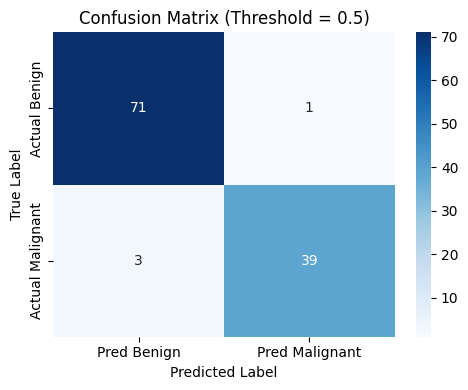


Top 5 features associated with MALIGNANCY:
            feature  coefficient
      texture_worst     1.434093
          radius_se     1.233325
     symmetry_worst     1.061264
concave points_mean     0.952813
    concavity_worst     0.911406

Top 5 features associated with BENIGN diagnosis:
             feature  coefficient
         symmetry_se    -0.330658
          texture_se    -0.407611
    compactness_mean    -0.439546
fractal_dimension_se    -0.593876
      compactness_se    -0.906925

--- Decision Threshold Analysis ---
Threshold  Precision   Recall     F1-Score  
------------------------------------------
0.1        0.891       0.976      0.932     
0.2        0.911       0.976      0.943     
0.3        0.976       0.976      0.976     
0.4        0.976       0.952      0.964     
0.5        0.975       0.929      0.951     
0.6        1.000       0.905      0.950     
0.7        1.000       0.905      0.950     
0.8        1.000       0.857      0.923     
0.9        1.000   

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------------------------------
# 1. LOAD & PREPROCESS DATA
# ----------------------------------------------------
df = pd.read_csv("data.csv")

# Drop unnecessary identifier and trailing empty column if present
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Encode target: Malignant (M) = 1 (Positive), Benign (B) = 0 (Negative)
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

print("Dataset Shape:", df.shape)
print("\nClass Distribution:\n", df["diagnosis"].value_counts())
print("\nTotal Missing Values:", df.isnull().sum().sum())

# ----------------------------------------------------
# 2. TRAIN-TEST SPLIT
# ----------------------------------------------------
X = df.drop(columns="diagnosis")
y = df["diagnosis"]

# Stratified split preserves the benign-to-malignant ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ----------------------------------------------------
# 3. PIPELINE SETUP & MODEL TRAINING
# ----------------------------------------------------
# Scaling inside the pipeline prevents data leakage from the test set
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

# ----------------------------------------------------
# 4. PREDICTIONS & EVALUATION (Default Threshold = 0.5)
# ----------------------------------------------------
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("\n--- Model Evaluation (Threshold = 0.5) ---")
print(f"Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f}")

print("\nFull Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

# Confusion matrix visualization
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Benign", "Pred Malignant"],
    yticklabels=["Actual Benign", "Actual Malignant"]
)
plt.title("Confusion Matrix (Threshold = 0.5)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

# ----------------------------------------------------
# 5. FEATURE IMPORTANCE (Standardized Coefficients)
# ----------------------------------------------------
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.named_steps["logreg"].coef_[0]
}).sort_values("coefficient", ascending=False)

print("\nTop 5 features associated with MALIGNANCY:")
print(coef_df.head(5).to_string(index=False))

print("\nTop 5 features associated with BENIGN diagnosis:")
print(coef_df.tail(5).to_string(index=False))

# ----------------------------------------------------
# 6. THRESHOLD TUNING (Precision vs. Recall Trade-off)
# ----------------------------------------------------
print("\n--- Decision Threshold Analysis ---")
print(f"{'Threshold':<10} {'Precision':<11} {'Recall':<10} {'F1-Score':<10}")
print("-" * 42)

for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred_t = (y_prob >= t).astype(int)
    p = precision_score(y_test, pred_t, zero_division=0)
    r = recall_score(y_test, pred_t)
    f1 = f1_score(y_test, pred_t)
    print(f"{t:<10.1f} {p:<11.3f} {r:<10.3f} {f1:<10.3f}")

(918, 12)
   Age Sex ChestPainType  ...  Oldpeak  ST_Slope  HeartDisease
0   40   M           ATA  ...      0.0        Up             0
1   49   F           NAP  ...      1.0      Flat             1
2   37   M           ATA  ...      0.0        Up             0
3   48   F           ASY  ...      1.5      Flat             1
4   54   M           NAP  ...      0.0        Up             0

[5 rows x 12 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null 

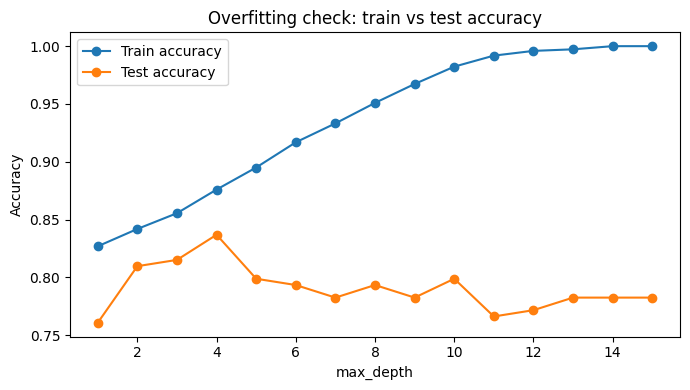


=== PRUNED TREE (max_depth=3) ===
Confusion matrix:
 [[68 14]
 [20 82]]
TN=68  FP=14  FN=20  TP=82
Train acc : 0.8556
Test acc  : 0.8152
Precision : 0.8542
Recall    : 0.8039
F1-score  : 0.8283

               precision    recall  f1-score   support

  No disease       0.77      0.83      0.80        82
     Disease       0.85      0.80      0.83       102

    accuracy                           0.82       184
   macro avg       0.81      0.82      0.81       184
weighted avg       0.82      0.82      0.82       184



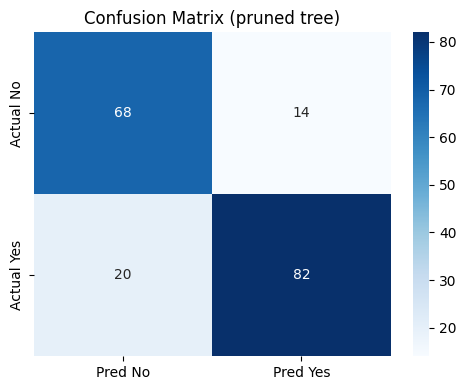

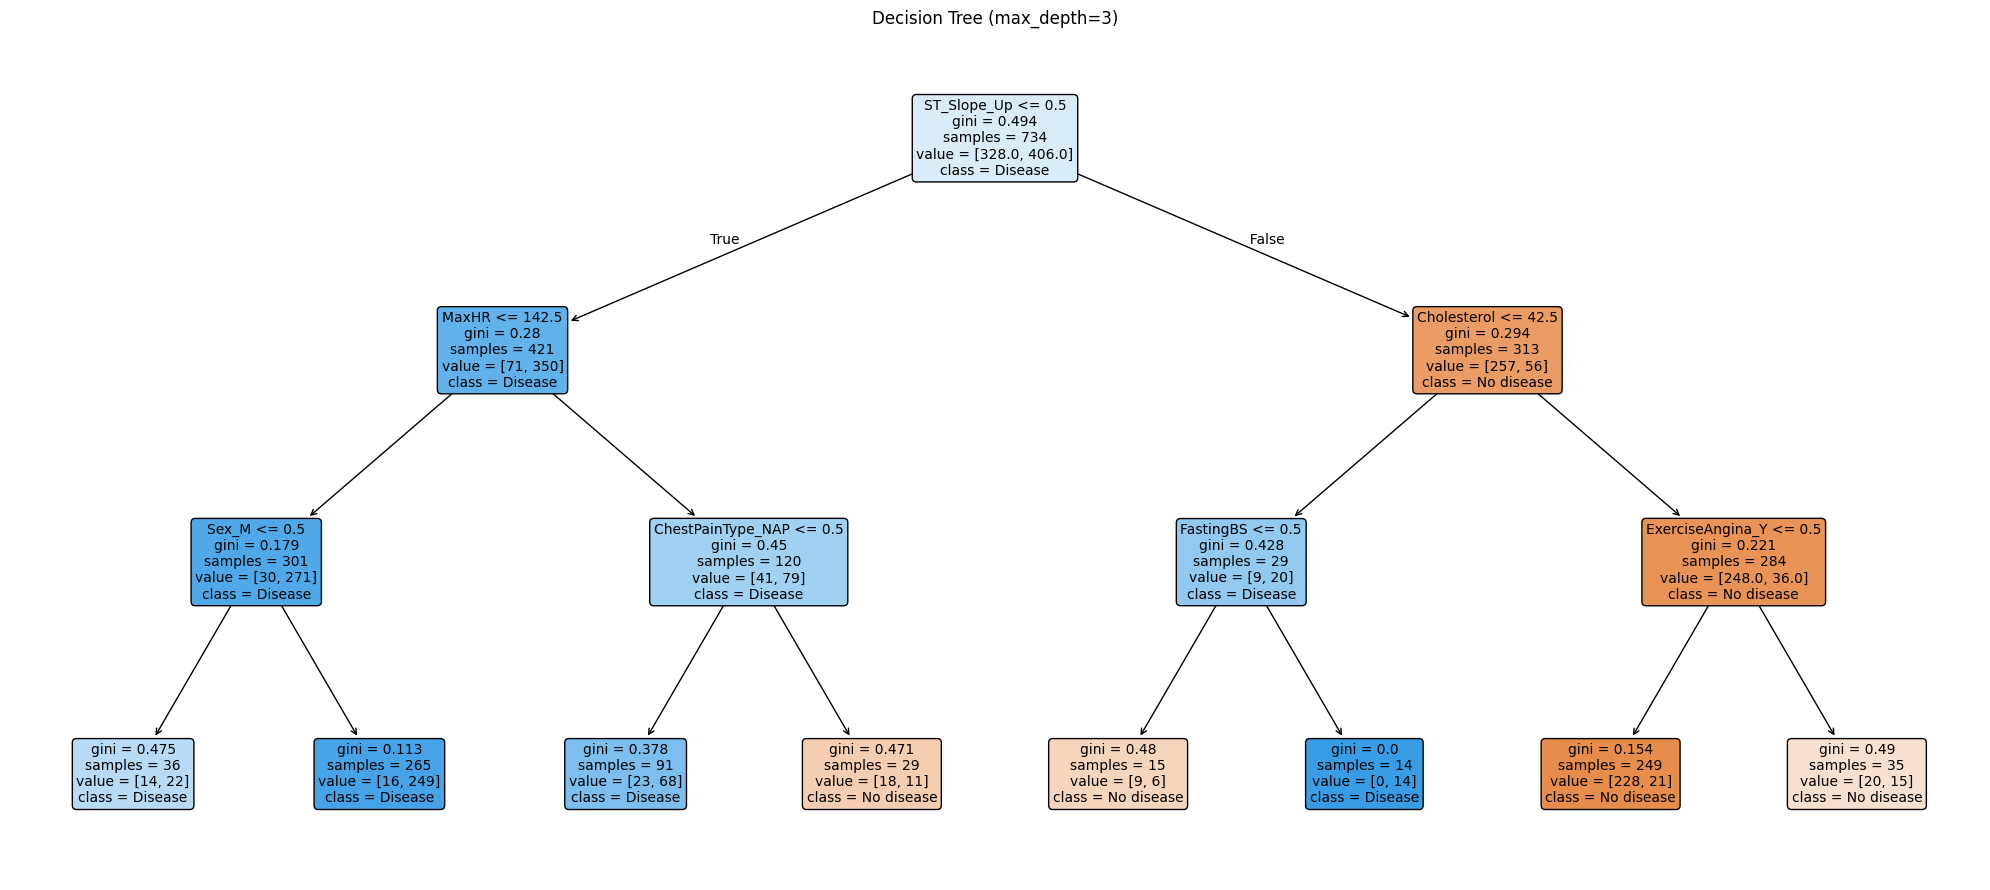


Tree as text rules:

|--- ST_Slope_Up <= 0.50
|   |--- MaxHR <= 142.50
|   |   |--- Sex_M <= 0.50
|   |   |   |--- class: 1
|   |   |--- Sex_M >  0.50
|   |   |   |--- class: 1
|   |--- MaxHR >  142.50
|   |   |--- ChestPainType_NAP <= 0.50
|   |   |   |--- class: 1
|   |   |--- ChestPainType_NAP >  0.50
|   |   |   |--- class: 0
|--- ST_Slope_Up >  0.50
|   |--- Cholesterol <= 42.50
|   |   |--- FastingBS <= 0.50
|   |   |   |--- class: 0
|   |   |--- FastingBS >  0.50
|   |   |   |--- class: 1
|   |--- Cholesterol >  42.50
|   |   |--- ExerciseAngina_Y <= 0.50
|   |   |   |--- class: 0
|   |   |--- ExerciseAngina_Y >  0.50
|   |   |   |--- class: 0


Feature importances:
 ST_Slope_Up          0.746126
Cholesterol          0.081400
MaxHR                0.049056
ExerciseAngina_Y     0.035502
Sex_M                0.033395
ChestPainType_NAP    0.029068
FastingBS            0.025452
dtype: float64


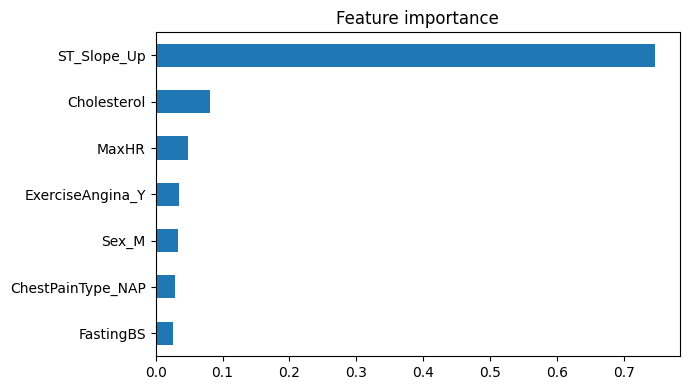

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score
)

# ---------------------------------------------------------------
# 1. LOAD + INSPECT
# ---------------------------------------------------------------
df = pd.read_csv("heart.csv")
print(df.shape)
print(df.head())
print(df.info())
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass balance (1 = heart disease):\n", df["HeartDisease"].value_counts())

# ---------------------------------------------------------------
# 2. PREPARE DATA
# ---------------------------------------------------------------
# Text columns (Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope)
# must become numbers. One-hot encoding makes one 0/1 column per category.
df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


# ---------------------------------------------------------------
# 3. TREE 1: NO LIMITS (grows until every leaf is pure -> overfits)
# ---------------------------------------------------------------
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)
print("\n=== UNRESTRICTED TREE ===")
print("Depth       :", full_tree.get_depth())
print("Leaves      :", full_tree.get_n_leaves())
print("Train acc   :", round(full_tree.score(X_train, y_train), 4))
print("Test acc    :", round(full_tree.score(X_test, y_test), 4))

# ---------------------------------------------------------------
# 4. FIND A GOOD max_depth (train vs test accuracy curve)
# ---------------------------------------------------------------
depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train))
    test_acc.append(t.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, marker="o", label="Train accuracy")
plt.plot(depths, test_acc, marker="o", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Overfitting check: train vs test accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("depth_vs_accuracy.png")
plt.show()

# ---------------------------------------------------------------
# 5. TREE 2: PRUNED TREE (controlled complexity)
# ---------------------------------------------------------------
tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,            # at most 3 questions deep
    min_samples_leaf=10,    # every leaf must contain at least 10 patients
    random_state=42
)
tree.fit(X_train, y_train)

# ---------------------------------------------------------------
# 6. EVALUATE
# ---------------------------------------------------------------
y_pred = tree.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("\n=== PRUNED TREE (max_depth=3) ===")
print("Confusion matrix:\n", cm)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("Train acc :", round(tree.score(X_train, y_train), 4))
print("Test acc  :", round(accuracy_score(y_test, y_pred), 4))
print("Precision :", round(precision_score(y_test, y_pred), 4))
print("Recall    :", round(recall_score(y_test, y_pred), 4))
print("F1-score  :", round(f1_score(y_test, y_pred), 4))
print("\n", classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred No", "Pred Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title("Confusion Matrix (pruned tree)")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

# ---------------------------------------------------------------
# 7. VISUALIZE THE TREE
# ---------------------------------------------------------------
plt.figure(figsize=(20, 9))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["No disease", "Disease"],
    filled=True,        # colour by majority class
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree (max_depth=3)")
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=150)
plt.show()

# The same tree as plain-text if/else rules
print("\nTree as text rules:\n")
print(export_text(tree, feature_names=list(X.columns)))

# ---------------------------------------------------------------
# 8. FEATURE IMPORTANCE
# ---------------------------------------------------------------
imp = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nFeature importances:\n", imp[imp > 0])

plt.figure(figsize=(7, 4))
imp[imp > 0].sort_values().plot(kind="barh")
plt.title("Feature importance")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()